In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('resources\diabetes_prediction_dataset.csv')
df.head()

<>:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
C:\Users\Choya\AppData\Local\Temp\ipykernel_17472\2741594956.py:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
  df = pd.read_csv('resources\diabetes_prediction_dataset.csv')


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 6.9 MB


In [4]:
(df['smoking_history'] == 'No Info').sum()

df['smoking_history'] = df['smoking_history'].replace('No Info', np.nan)
df['smoking_history'].isna().sum()   
df


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,NaN,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,NaN,27.32,6.2,90,0
99996,Female,2.0,0,0,NaN,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


In [5]:
df = df.dropna()
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
5,Female,20.0,0,0,never,27.32,6.6,85,0
...,...,...,...,...,...,...,...,...,...
99992,Female,26.0,0,0,never,34.34,6.5,160,0
99993,Female,40.0,0,0,never,40.69,3.5,155,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


In [6]:
%pip install seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

In [8]:
df['gender'] = pd.factorize(df['gender'])[0]
df
# female = 0
# male = 1

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,0,80.0,0,1,never,25.19,6.6,140,0
2,1,28.0,0,0,never,27.32,5.7,158,0
3,0,36.0,0,0,current,23.45,5.0,155,0
4,1,76.0,1,1,current,20.14,4.8,155,0
5,0,20.0,0,0,never,27.32,6.6,85,0
...,...,...,...,...,...,...,...,...,...
99992,0,26.0,0,0,never,34.34,6.5,160,0
99993,0,40.0,0,0,never,40.69,3.5,155,0
99997,1,66.0,0,0,former,27.83,5.7,155,0
99998,0,24.0,0,0,never,35.42,4.0,100,0


In [9]:
df['smoking_history'] = pd.factorize(df['smoking_history'])[0]
df
# never = 0
# current = 1
# former = 2

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,0,80.0,0,1,0,25.19,6.6,140,0
2,1,28.0,0,0,0,27.32,5.7,158,0
3,0,36.0,0,0,1,23.45,5.0,155,0
4,1,76.0,1,1,1,20.14,4.8,155,0
5,0,20.0,0,0,0,27.32,6.6,85,0
...,...,...,...,...,...,...,...,...,...
99992,0,26.0,0,0,0,34.34,6.5,160,0
99993,0,40.0,0,0,0,40.69,3.5,155,0
99997,1,66.0,0,0,2,27.83,5.7,155,0
99998,0,24.0,0,0,0,35.42,4.0,100,0


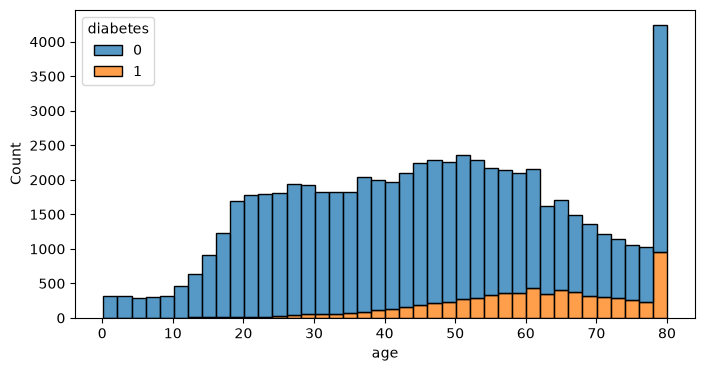

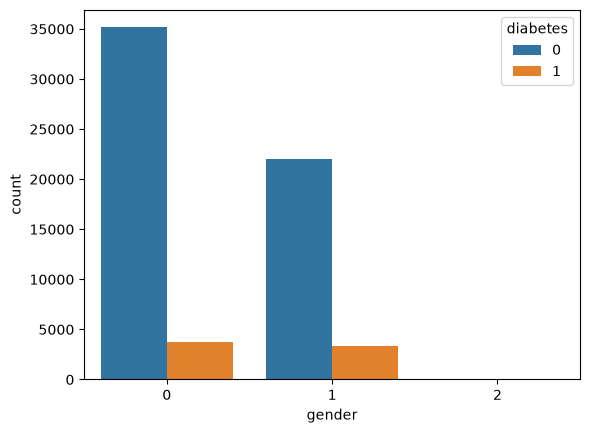

In [10]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='age', hue='diabetes', bins=40, multiple='stack')
plt.show()

sns.countplot(x='gender', hue='diabetes', data=df)
plt.show()

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

Train Models

In [12]:
X = df.drop('diabetes', axis = 1)
X

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level
0,0,80.0,0,1,0,25.19,6.6,140
2,1,28.0,0,0,0,27.32,5.7,158
3,0,36.0,0,0,1,23.45,5.0,155
4,1,76.0,1,1,1,20.14,4.8,155
5,0,20.0,0,0,0,27.32,6.6,85
...,...,...,...,...,...,...,...,...
99992,0,26.0,0,0,0,34.34,6.5,160
99993,0,40.0,0,0,0,40.69,3.5,155
99997,1,66.0,0,0,2,27.83,5.7,155
99998,0,24.0,0,0,0,35.42,4.0,100


In [13]:
y = df['diabetes']
y

0        0
2        0
3        0
4        0
5        0
        ..
99992    0
99993    0
99997    0
99998    0
99999    0
Name: diabetes, Length: 64184, dtype: int64

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [15]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

rf = RandomForestClassifier(random_state=42, class_weight='balanced')
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_s, y_train)
pred_knn = knn.predict(X_test_s)

lr = LogisticRegression()
lr.fit(X_train_s, y_train)
pred_lr = lr.predict(X_test_s)

Evaluate

In [17]:
from sklearn.metrics import classification_report, confusion_matrix

results = {'Random Forest': pred_rf, 'KNN': pred_knn, 'Logistic Regression': pred_lr}

for name, pred in results.items():
    print(name)
    print(classification_report(y_test, pred, target_names=['No diabetes', 'Diabetes']))

Random Forest
              precision    recall  f1-score   support

 No diabetes       0.97      0.97      0.97     11428
    Diabetes       0.78      0.75      0.76      1409

    accuracy                           0.95     12837
   macro avg       0.87      0.86      0.87     12837
weighted avg       0.95      0.95      0.95     12837

KNN
              precision    recall  f1-score   support

 No diabetes       0.96      0.98      0.97     11428
    Diabetes       0.82      0.65      0.72      1409

    accuracy                           0.95     12837
   macro avg       0.89      0.82      0.85     12837
weighted avg       0.94      0.95      0.94     12837

Logistic Regression
              precision    recall  f1-score   support

 No diabetes       0.96      0.99      0.97     11428
    Diabetes       0.86      0.64      0.74      1409

    accuracy                           0.95     12837
   macro avg       0.91      0.81      0.85     12837
weighted avg       0.95      0.95   

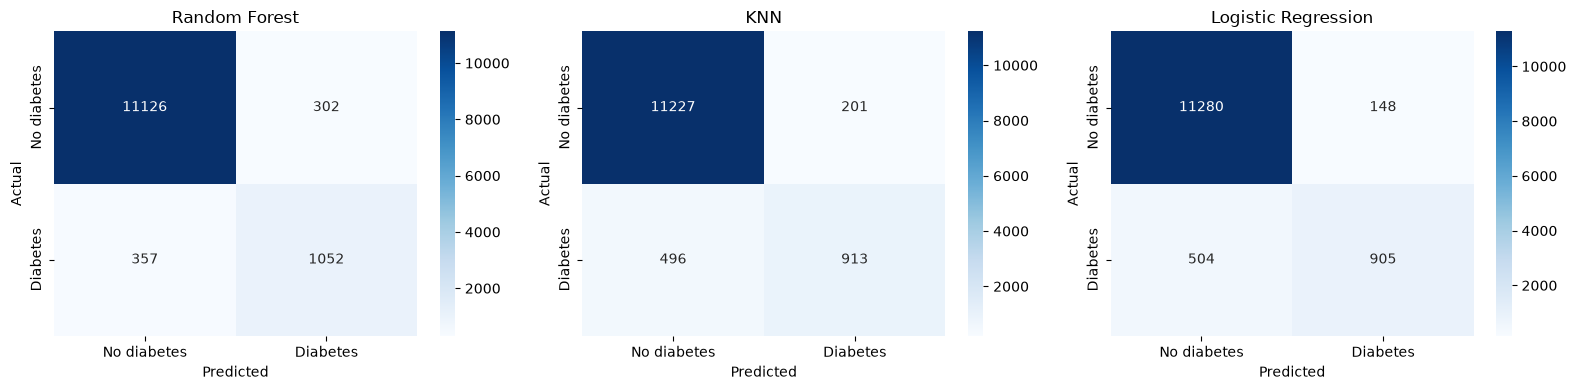

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, pred) in zip(axes, results.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=['No diabetes', 'Diabetes'],
                yticklabels=['No diabetes', 'Diabetes'], ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

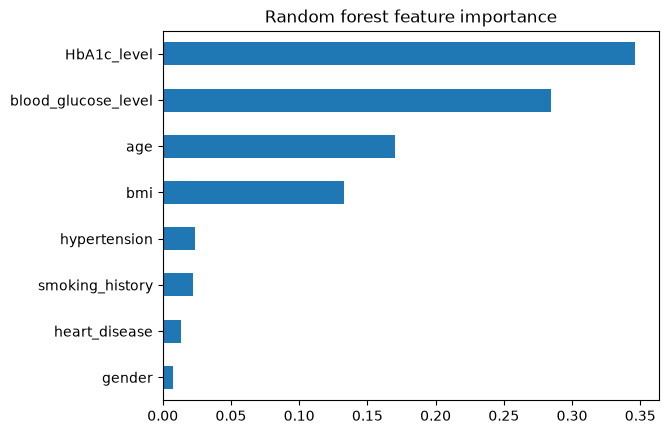

In [19]:
pd.Series(rf.feature_importances_, index=X.columns).sort_values().plot(kind='barh')
plt.title('Random forest feature importance')
plt.show()

Thus, HbA1c level and blood glucose level are the standard diagnostic measures for diabetes, so we know whether a person has the condition. Age and BMI are risk factors that causes a person to have a higher chance of developing diabetes. Hypertension, smoking history, heart disease and gender are less likely to cause a person to develop diabetes.